# Data Mining Final Project - Online Shoppers Purchase Prediction

Course: Data Mining (AIE323), Alamein International University

Project 6: E-Commerce Purchase Prediction and Behavior Mining

| # | Name | Student ID |
|---|------|------------|
| 1 | Mohamed Alaa Fathy | 23100830 |
| 2 | Ahmed Ali Saleh Mohamed Elhagry | 23102246 |
| 3 | Ahmed Abdelsalam Soliman Dwedar | 23100757 |
| 4 | Youssef Barakat Mohamed Aboyoussef | 23101613 |
| 5 | Mahmoud Hossam Fath Elsaied | 23101597 |
| 6 |  |  |

In this project we try to predict if an online shopping session will end with a purchase, using what the visitor did during the session (pages visited, time spent, bounce and exit rates, month, type of visitor and so on). We also group the sessions with K-Means to see what kinds of browsing behavior exist. At the end we save the trained models and use them in a Streamlit app.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
import json
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display
from scipy.stats import loguniform

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif, RFE
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
                             silhouette_score, davies_bouldin_score, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# the notebook lives in notebooks/, features.py is in the repo root
ROOT = Path.cwd() if (Path.cwd() / "features.py").exists() else Path.cwd().parent
sys.path.append(str(ROOT))
from features import add_features, INPUT_COLS, NUM_INPUTS, CAT_COLS, NEW_COLS

FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=120)
    plt.show()
    plt.close()

## 1. Dataset Understanding

The data is the "Online Shoppers Purchasing Intention" dataset from the UCI Machine Learning Repository (id 468), published by Sakar et al. (2019) in Neural Computing and Applications. Each row is one session on an online shop. The sessions were collected over one year and each session belongs to a different user, so the data is not dominated by one campaign or one heavy user.

In [2]:
df = pd.read_csv(ROOT / "data" / "online_shoppers_intention.csv")
print("rows:", df.shape[0], "columns:", df.shape[1])
display(df.head())
print(df.dtypes)

rows: 12330 columns: 18


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


| Column | Type | Meaning |
|---|---|---|
| Administrative | numerical (count) | number of account/administrative pages visited in the session |
| Administrative_Duration | numerical (seconds) | total time spent on those pages |
| Informational | numerical (count) | number of informational pages (about us, contact, shipping info) |
| Informational_Duration | numerical (seconds) | time spent on informational pages |
| ProductRelated | numerical (count) | number of product pages visited |
| ProductRelated_Duration | numerical (seconds) | time spent on product pages |
| BounceRates | numerical (0 to 0.2) | Google Analytics bounce rate of the visited pages, the share of visitors who entered on that page and left without doing anything else |
| ExitRates | numerical (0 to 0.2) | Google Analytics exit rate, the share of page views where that page was the last one in the session |
| PageValues | numerical | Google Analytics page value, the average value of a page that users visited before completing a transaction |
| SpecialDay | numerical (0 to 1) | how close the session date is to a special day like Valentine's Day or Mother's Day, 1 is the peak |
| Month | categorical | month of the session |
| OperatingSystems | categorical (code) | operating system, stored as an integer code |
| Browser | categorical (code) | browser, integer code |
| Region | categorical (code) | region of the user, integer code |
| TrafficType | categorical (code) | how the visitor arrived (ads, direct, referral...), integer code |
| VisitorType | categorical | Returning_Visitor, New_Visitor or Other |
| Weekend | boolean | whether the session was on a weekend |
| Revenue | boolean (target) | whether the session ended with a purchase |

So we have 10 numerical columns and 7 categorical/boolean inputs, plus the target Revenue. One thing to be careful with: OperatingSystems, Browser, Region and TrafficType look numeric but they are just codes, so a bigger number does not mean "more" of anything. We treat them as categories.

## 2. Data Quality Check

In [3]:
print("total missing values:", df.isnull().sum().sum())
print("duplicate rows:", df.duplicated().sum())
num_raw = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
           "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
display(df[num_raw].describe().T.round(2))
print("negative values:", (df[num_raw] < 0).sum().sum())
print(df["Month"].value_counts())
print(df["VisitorType"].value_counts())

total missing values: 0
duplicate rows: 125


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.32,3.32,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12330.0,80.82,176.78,0.0,0.00,7.50,93.26,3398.75
Informational,12330.0,0.50,1.27,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12330.0,34.47,140.75,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12330.0,31.73,44.48,0.0,7.00,18.00,38.00,705.00
ProductRelated_Duration,12330.0,1194.75,1913.67,0.0,184.14,598.94,1464.16,63973.52
BounceRates,12330.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12330.0,0.04,0.05,0.0,0.01,0.03,0.05,0.20
PageValues,12330.0,5.89,18.57,0.0,0.00,0.00,0.00,361.76
SpecialDay,12330.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


negative values: 0
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64


In [4]:
# what do the duplicated rows look like
dups = df[df.duplicated(keep=False)]
print("rows involved in duplicates:", len(dups))
print("buyers among them:", dups["Revenue"].sum())
print("share with 0 seconds on product pages:", round((dups["ProductRelated_Duration"] == 0).mean(), 3))
print("share with bounce rate 0.2:", round((dups["BounceRates"] == 0.2).mean(), 3))

rows involved in duplicates: 201
buyers among them: 0
share with 0 seconds on product pages: 1.0
share with bounce rate 0.2: 1.0


There are no missing values and no negative values, so no imputation was needed. There are 125 duplicated rows. When we looked at them, all 201 rows involved in duplicates have 0 seconds on product pages and a bounce rate of 0.2, and none of them is a buyer. They look like sessions where someone opened one page and left, so different visitors end up with exactly the same row. We still drop the exact copies in section 4, because the same row could otherwise land in both train and test.

The month counts show that January and April are not in the data at all, and May (3,364) and November (2,998) have far more sessions than the other months. Most visitors are returning visitors (10,551 of 12,330).

## 3. Exploratory Data Analysis

Revenue
False    10422
True      1908
Name: count, dtype: int64
conversion rate: 0.1547


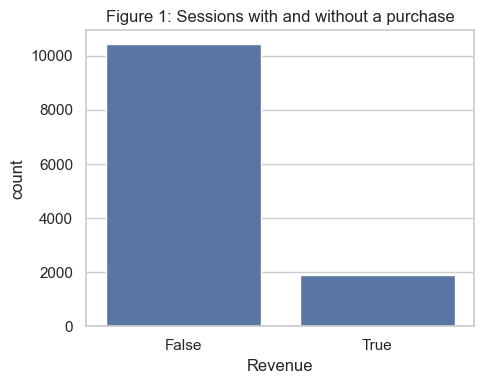

In [5]:
print(df["Revenue"].value_counts())
print("conversion rate:", round(df["Revenue"].mean(), 4))
plt.figure(figsize=(5, 4))
sns.countplot(x="Revenue", data=df)
plt.title("Figure 1: Sessions with and without a purchase")
save("01_revenue_balance.png")

Only 1,908 of the 12,330 sessions (15.5%) ended with a purchase. The classes are clearly imbalanced, so a model that always says "no purchase" would already be about 84.5% accurate. This is why we use PR-AUC, recall, precision and F1 later instead of accuracy.

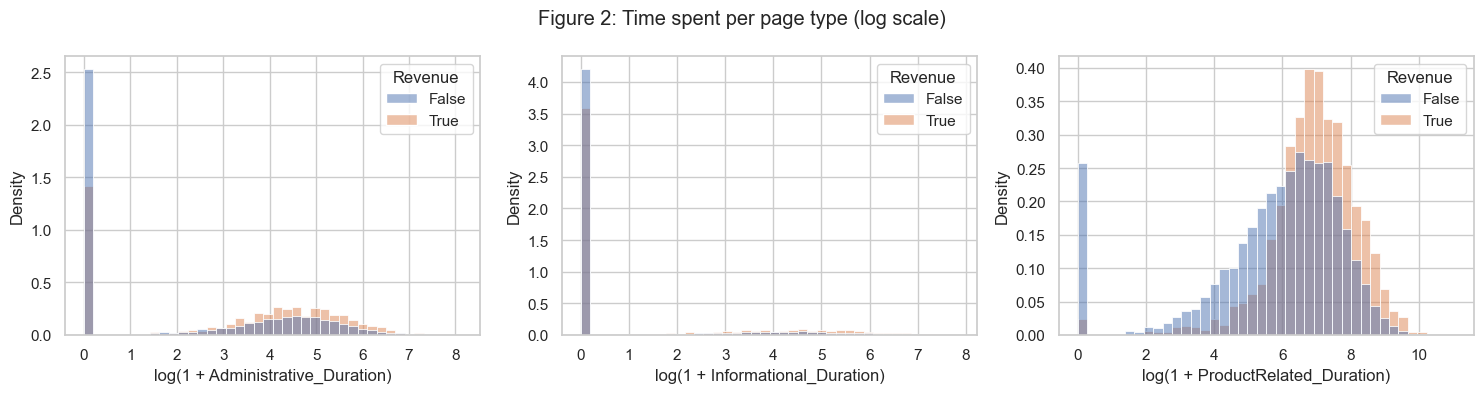

         Administrative_Duration  Informational_Duration  \
Revenue                                                    
False                   0.000000                     0.0   
True                   52.366667                     0.0   

         ProductRelated_Duration  
Revenue                           
False                  510.19000  
True                  1109.90625  
share of sessions with 0 sec on admin / info pages: 0.479 0.805


In [6]:
dur_cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, dur_cols):
    tmp = df.assign(v=np.log1p(df[col]))
    sns.histplot(data=tmp, x="v", hue="Revenue", bins=40, stat="density", common_norm=False, ax=ax)
    ax.set_xlabel("log(1 + " + col + ")")
fig.suptitle("Figure 2: Time spent per page type (log scale)")
save("02_durations_by_revenue.png")
print(df.groupby("Revenue")[dur_cols].median())
print("share of sessions with 0 sec on admin / info pages:",
      round((df["Administrative_Duration"] == 0).mean(), 3), round((df["Informational_Duration"] == 0).mean(), 3))

All three duration columns are very right skewed, that is why we plot them on a log scale. Many sessions spend zero time on administrative pages (47.9%) and on informational pages (80.5%). Buyers spend clearly more time on product pages: the median is about 1,110 seconds for buyers against 510 seconds for non-buyers. The median administrative time is 52 seconds for buyers and 0 for non-buyers.

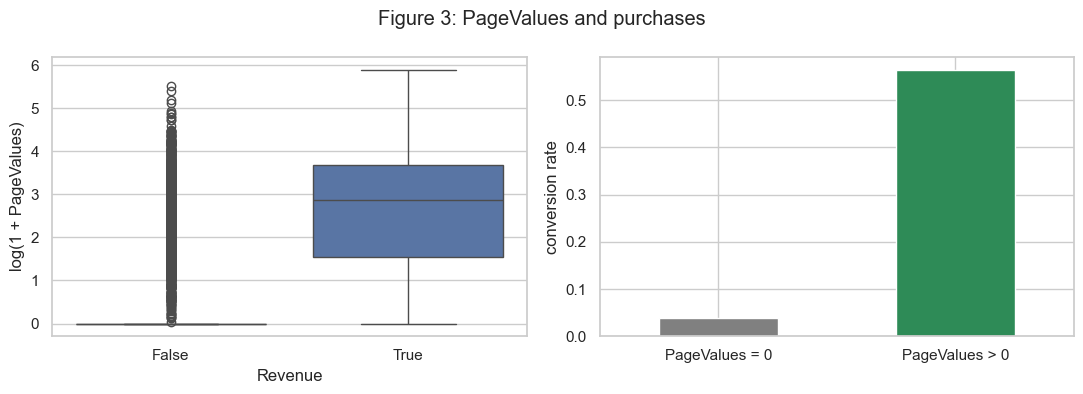

          mean  median
Revenue               
False     1.98    0.00
True     27.26   16.76
share of sessions with PageValues > 0: 0.221
PageValues = 0    0.039
PageValues > 0    0.563
Name: Revenue, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=df.assign(logpv=np.log1p(df["PageValues"])), x="Revenue", y="logpv", ax=axes[0])
axes[0].set_ylabel("log(1 + PageValues)")
pv = df.groupby(df["PageValues"] > 0)["Revenue"].mean()
pv.index = ["PageValues = 0", "PageValues > 0"]
pv.plot(kind="bar", ax=axes[1], color=["grey", "seagreen"], rot=0)
axes[1].set_ylabel("conversion rate")
fig.suptitle("Figure 3: PageValues and purchases")
save("03_pagevalues.png")
print(df.groupby("Revenue")["PageValues"].agg(["mean", "median"]).round(2))
print("share of sessions with PageValues > 0:", round((df["PageValues"] > 0).mean(), 3))
print(pv.round(3))

This is the strongest pattern in the dataset. Only 22.1% of sessions have PageValues above 0, but 56.3% of those sessions end with a purchase, compared with 3.9% when PageValues is 0. The median PageValues of buyers is 16.8 and for non-buyers it is 0. We come back to this column in section 9, because PageValues is calculated from pages that came before a transaction, so part of its strength may come from the purchase itself.

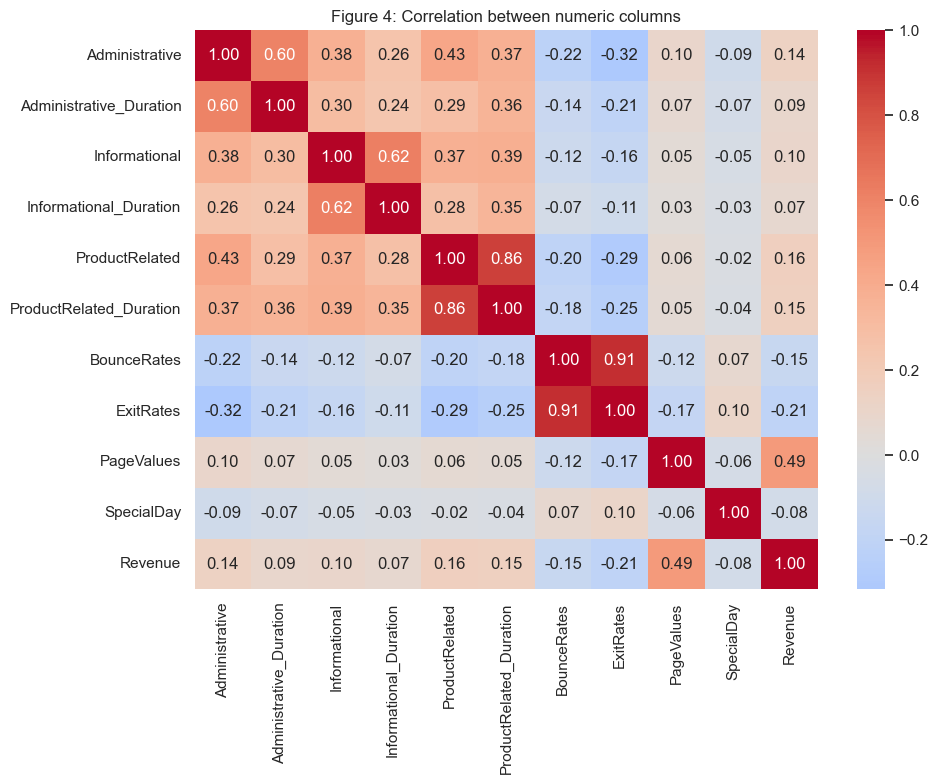

PageValues                 0.493
ProductRelated             0.159
ProductRelated_Duration    0.152
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
Informational_Duration     0.070
SpecialDay                -0.082
BounceRates               -0.151
ExitRates                 -0.207
Name: Revenue, dtype: float64
Administrative  Administrative_Duration    0.602
Informational   Informational_Duration     0.619
ProductRelated  ProductRelated_Duration    0.861
BounceRates     ExitRates                  0.913
dtype: float64


In [8]:
corr = df[num_raw + ["Revenue"]].astype(float).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Figure 4: Correlation between numeric columns")
save("04_correlation.png")
print(corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3))
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.6].round(3))

PageValues has by far the highest correlation with Revenue (0.49). ExitRates (-0.21) and BounceRates (-0.15) are negative, so sessions where people leave quickly buy less. The page counts and durations are positive but weaker (0.07 to 0.16).

Some inputs are strongly correlated with each other: BounceRates with ExitRates (0.91), ProductRelated with ProductRelated_Duration (0.86), and each page count with its own duration (around 0.6). This does not hurt the tree models much, but it is one reason we also tried feature selection and PCA later.

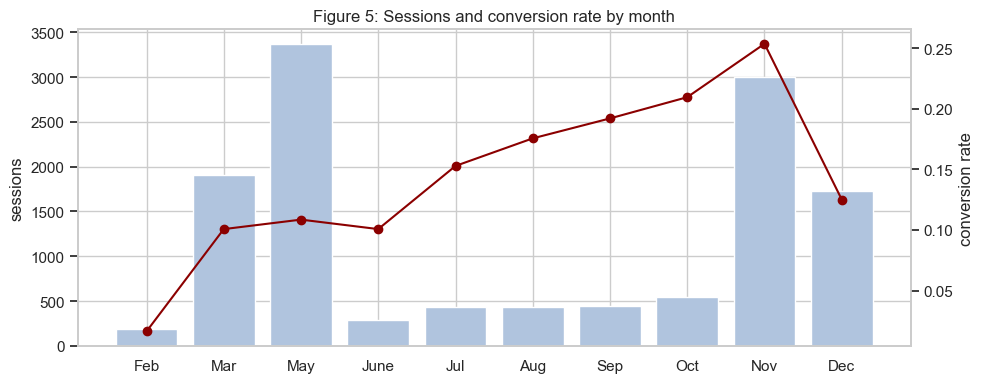

       count   mean
Month              
Feb      184  0.016
Mar     1907  0.101
May     3364  0.109
June     288  0.101
Jul      432  0.153
Aug      433  0.176
Sep      448  0.192
Oct      549  0.209
Nov     2998  0.254
Dec     1727  0.125


In [9]:
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
m = df.groupby("Month")["Revenue"].agg(["count", "mean"]).reindex(month_order)
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(m.index, m["count"], color="lightsteelblue")
ax1.set_ylabel("sessions")
ax2 = ax1.twinx()
ax2.plot(m.index, m["mean"], color="darkred", marker="o")
ax2.set_ylabel("conversion rate")
ax2.grid(False)
plt.title("Figure 5: Sessions and conversion rate by month")
save("05_month.png")
print(m.round(3))

The month has a big effect. November has the highest conversion rate (25.4%) and the second most sessions (2,998), probably because of the shopping period before the end of the year. May has the most sessions (3,364) but only 10.9% of them convert. February is the weakest month with only 184 sessions and 1.6% conversion. From July to October the conversion goes up step by step, from 15.3% to 20.9%.

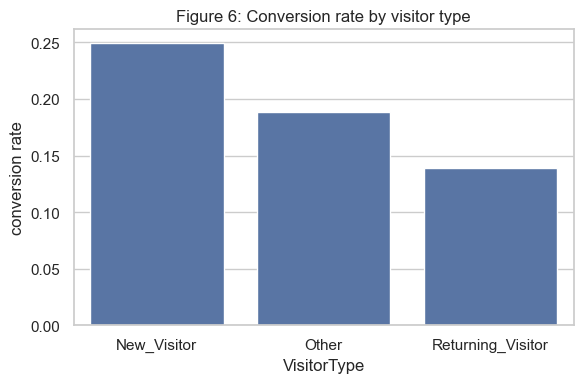

                   count   mean
VisitorType                    
New_Visitor         1694  0.249
Other                 85  0.188
Returning_Visitor  10551  0.139


In [10]:
vt = df.groupby("VisitorType")["Revenue"].agg(["count", "mean"])
plt.figure(figsize=(6, 4))
sns.barplot(x=vt.index, y=vt["mean"])
plt.ylabel("conversion rate")
plt.title("Figure 6: Conversion rate by visitor type")
save("06_visitor_type.png")
print(vt.round(3))

New visitors convert more often (24.9%) than returning visitors (13.9%). We expected the opposite at first. One possible reason is that returning visitors include many people who come back only to browse or compare prices, while a new visitor often arrives looking for a specific product. Returning visitors are still the large majority, so in absolute numbers most buyers are returning visitors (about 1,470 against 420).

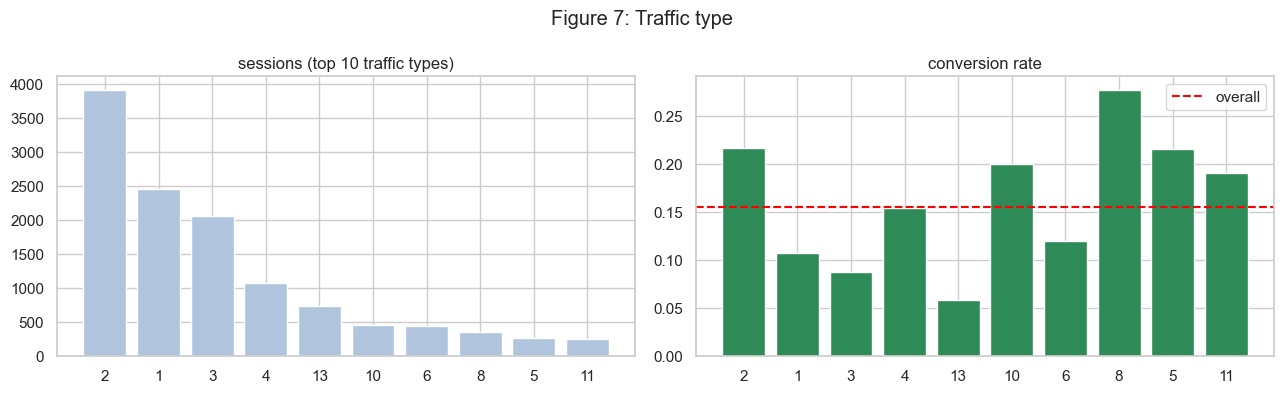

             count   mean
TrafficType              
2             3913  0.216
1             2451  0.107
3             2052  0.088
4             1069  0.154
13             738  0.058
10             450  0.200
6              444  0.119
8              343  0.277
5              260  0.215
11             247  0.190


In [11]:
tt = df.groupby("TrafficType")["Revenue"].agg(["count", "mean"]).sort_values("count", ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(tt.index.astype(str), tt["count"], color="lightsteelblue")
axes[0].set_title("sessions (top 10 traffic types)")
axes[1].bar(tt.index.astype(str), tt["mean"], color="seagreen")
axes[1].axhline(df["Revenue"].mean(), color="red", linestyle="--", label="overall")
axes[1].set_title("conversion rate")
axes[1].legend()
fig.suptitle("Figure 7: Traffic type")
save("07_traffic_type.png")
print(tt.round(3))

Traffic type 2 is the biggest source (3,913 sessions) and it also converts well (21.6%). Some sources bring many visitors who rarely buy, for example type 3 (2,052 sessions, 8.8%) and type 13 (738 sessions, 5.8%). Type 8 has the highest conversion of the top 10 (27.7%) but brings only 343 sessions. The dataset only gives codes, so we cannot say which real channel each type is.

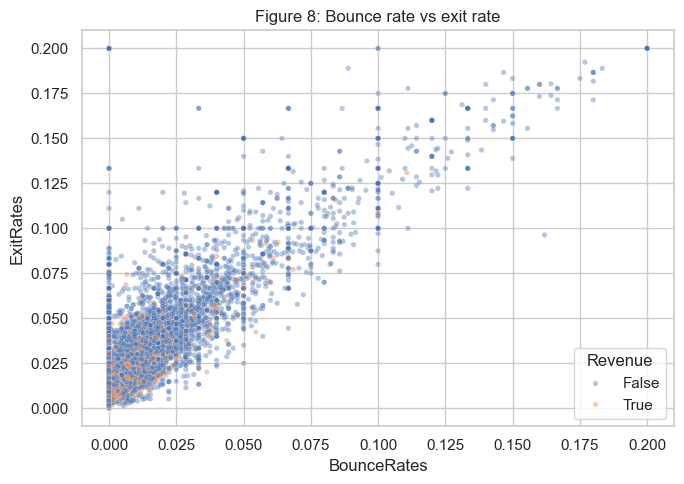

         BounceRates  ExitRates
Revenue                        
False         0.0043     0.0286
True          0.0000     0.0160
ExitRates
(-0.001, 0.0143]    0.265
(0.0143, 0.0252]    0.203
(0.0252, 0.05]      0.113
(0.05, 0.2]         0.028
Name: Revenue, dtype: float64


In [12]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="BounceRates", y="ExitRates", hue="Revenue", alpha=0.4, s=15)
plt.title("Figure 8: Bounce rate vs exit rate")
save("08_bounce_exit.png")
print(df.groupby("Revenue")[["BounceRates", "ExitRates"]].median().round(4))
q = pd.qcut(df["ExitRates"], 4, duplicates="drop")
print(df.groupby(q)["Revenue"].mean().round(3))

BounceRates and ExitRates move together, as the 0.91 correlation already showed, and there is a group of points at 0.2 / 0.2 which are the one-page sessions. Buyers are almost all in the bottom left corner. When we split ExitRates into quarters, conversion falls from 26.5% in the lowest quarter to only 2.8% in the highest one.

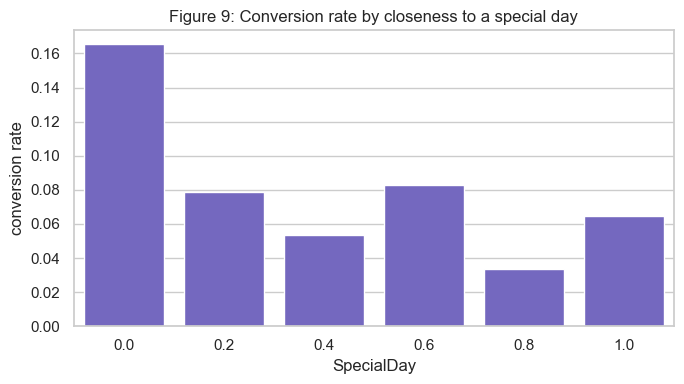

            count   mean
SpecialDay              
0.0         11079  0.165
0.2           178  0.079
0.4           243  0.053
0.6           351  0.083
0.8           325  0.034
1.0           154  0.065
months with SpecialDay > 0: {'May': 1172, 'Feb': 79}


In [13]:
sd = df.groupby("SpecialDay")["Revenue"].agg(["count", "mean"])
plt.figure(figsize=(7, 4))
sns.barplot(x=sd.index.astype(str), y=sd["mean"], color="slateblue")
plt.xlabel("SpecialDay")
plt.ylabel("conversion rate")
plt.title("Figure 9: Conversion rate by closeness to a special day")
save("09_special_day.png")
print(sd.round(3))
print("months with SpecialDay > 0:", df[df["SpecialDay"] > 0]["Month"].value_counts().to_dict())

This one surprised us. Sessions close to a special day convert less, not more. When SpecialDay is 0 the conversion is 16.5%, but for every non-zero value it is between 3.4% and 8.3%. All special-day sessions are in May (1,172) and February (79), so they are around Mother's Day and Valentine's Day, and both of these months are weak months anyway. So part of this effect is probably the month. Another explanation is that people look for gift ideas some days before the occasion and buy later or somewhere else.

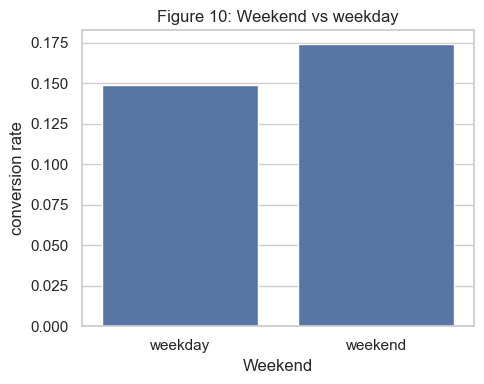

         count   mean
Weekend              
False     9462  0.149
True      2868  0.174


In [14]:
wk = df.groupby("Weekend")["Revenue"].agg(["count", "mean"])
plt.figure(figsize=(5, 4))
sns.barplot(x=wk.index.map({False: "weekday", True: "weekend"}), y=wk["mean"])
plt.ylabel("conversion rate")
plt.title("Figure 10: Weekend vs weekday")
save("10_weekend.png")
print(wk.round(3))

Weekend sessions convert a little more (17.4%) than weekday sessions (14.9%). The difference is small compared with month or PageValues, and most traffic (9,462 sessions) is on weekdays.

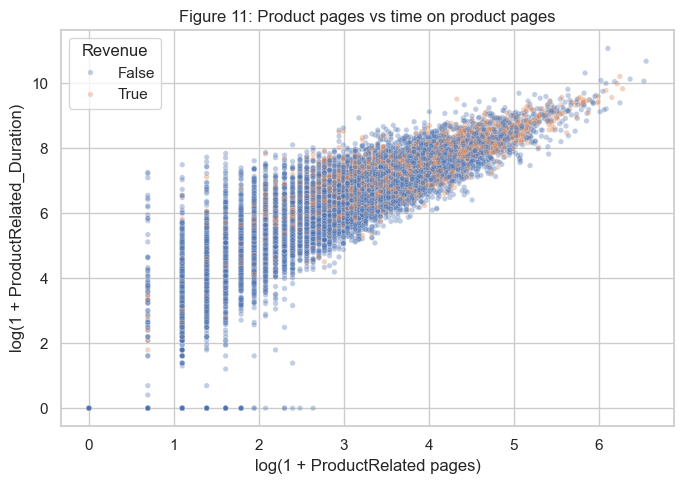

         ProductRelated  ProductRelated_Duration
Revenue                                         
False              16.0                510.19000
True               29.0               1109.90625
ProductRelated
(-0.001, 7.0]    0.051
(7.0, 18.0]      0.139
(18.0, 38.0]     0.197
(38.0, 705.0]    0.236
Name: Revenue, dtype: float64


In [15]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=np.log1p(df["ProductRelated"]), y=np.log1p(df["ProductRelated_Duration"]),
                hue=df["Revenue"], alpha=0.35, s=15)
plt.xlabel("log(1 + ProductRelated pages)")
plt.ylabel("log(1 + ProductRelated_Duration)")
plt.title("Figure 11: Product pages vs time on product pages")
save("11_product_pages.png")
print(df.groupby("Revenue")[["ProductRelated", "ProductRelated_Duration"]].median())
pp = pd.qcut(df["ProductRelated"], 4)
print(df.groupby(pp)["Revenue"].mean().round(3))

The number of product pages and the time on them are strongly linked, which makes sense since every page takes some time. Buyers look at more products (median 29 pages) than non-buyers (16 pages). Conversion goes up with the number of product pages: 5.1% for sessions with 7 or fewer product pages and 23.6% for sessions with more than 38.

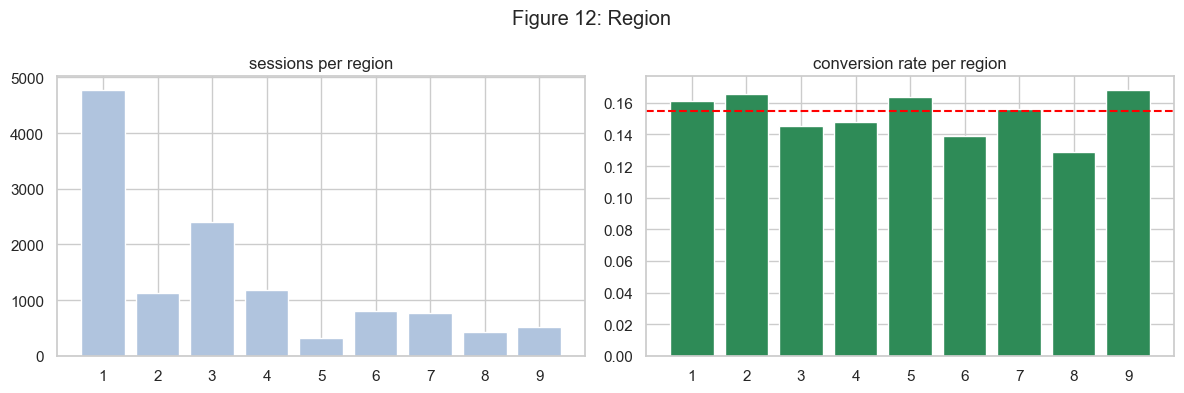

        count   mean
Region              
1        4780  0.161
2        1136  0.165
3        2403  0.145
4        1182  0.148
5         318  0.164
6         805  0.139
7         761  0.156
8         434  0.129
9         511  0.168


In [16]:
rg = df.groupby("Region")["Revenue"].agg(["count", "mean"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(rg.index.astype(str), rg["count"], color="lightsteelblue")
axes[0].set_title("sessions per region")
axes[1].bar(rg.index.astype(str), rg["mean"], color="seagreen")
axes[1].axhline(df["Revenue"].mean(), color="red", linestyle="--")
axes[1].set_title("conversion rate per region")
fig.suptitle("Figure 12: Region")
save("12_region.png")
print(rg.round(3))

Region 1 has the most sessions (4,780), then region 3 (2,403). The conversion rate is similar in all regions, between 12.9% and 16.8%. So region does not look useful for predicting purchases, and we see the same thing later in the feature importance.

## 4. Data Preparation

First we remove the duplicates, then we split into train and test before fitting anything. Every step that learns something from the data (scaling, encoding, SMOTE, feature selection, K-Means) is fitted on the training part only.

In [17]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("removed", before - len(df), "duplicate rows, left:", len(df))

X = df[INPUT_COLS]
y = df["Revenue"].astype(int)
# split first so the test set is never seen while building the model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", X_train.shape, "test:", X_test.shape)
print("buyer share train:", round(y_train.mean(), 4), "test:", round(y_test.mean(), 4))

removed 125 duplicate rows, left: 12205
train: (9764, 17) test: (2441, 17)
buyer share train: 0.1563 test: 0.1565


### Outliers

In [18]:
rows = []
for c in num_raw[:-1]:
    q1, q3 = X_train[c].quantile([0.25, 0.75])
    mask = X_train[c] > q3 + 1.5 * (q3 - q1)
    rows.append([c, mask.sum(), round(mask.mean() * 100, 1), round(y_train[mask].mean(), 3) if mask.sum() else np.nan])
out = pd.DataFrame(rows, columns=["column", "outliers (IQR)", "% of train", "buy rate in outliers"])
display(out)
print("buy rate in whole train:", round(y_train.mean(), 3))
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "PageValues"]
print(pd.DataFrame({"skew before": X_train[log_cols].skew(), "skew after log1p": np.log1p(X_train[log_cols]).skew()}).round(2))

,column,outliers (IQR),% of train,buy rate in outliers
0,Administrative,325,3.3,0.268
1,Administrative_Duration,937,9.6,0.235
2,Informational,2107,21.6,0.226
3,Informational_Duration,1917,19.6,0.227
4,ProductRelated,767,7.9,0.286
5,ProductRelated_Duration,751,7.7,0.297
6,BounceRates,1127,11.5,0.019
7,ExitRates,780,8.0,0.005
8,PageValues,2187,22.4,0.561


buy rate in whole train: 0.156
                         skew before  skew after log1p
Administrative                  1.99              0.56
Administrative_Duration         5.68              0.24
Informational                   4.10              2.01
Informational_Duration          7.54              1.91
ProductRelated                  4.39             -0.04
ProductRelated_Duration         7.87             -1.43
PageValues                      6.55              1.80


The IQR rule marks a lot of values as outliers, from 3.3% of training rows for Administrative up to 22.4% for PageValues (the upper quartile of PageValues is 0, so every non-zero value counts as an outlier). These values are not errors. In most columns the outlier rows buy more often than average, for example 56.1% for PageValues outliers and 29.7% for ProductRelated_Duration outliers, against 15.6% overall. Removing them would throw away a big part of the buyers, so we kept all rows.

Instead we reduce the skew with log1p and then use StandardScaler. For example ProductRelated goes from a skewness of 4.39 to -0.04. log1p is fine with the many zeros because log(1 + 0) = 0. BounceRates and ExitRates have a large share of outliers too, but they are bounded between 0 and 0.2, so we only scale them.

### Encoding, scaling and the pipeline

- Month, VisitorType, OperatingSystems, Browser, Region and TrafficType are one-hot encoded. We use `handle_unknown="ignore"` so a code that never appeared in training (for example a new browser code in the app) does not crash the model, it just gets all zeros.
- Weekend is turned into 0/1 inside `add_features`.
- Counts, durations and PageValues go through log1p and then StandardScaler. The other numeric columns only get StandardScaler. Scaling matters for logistic regression, and it does not hurt the tree models.
- All of this sits in one sklearn Pipeline together with the model, so the app loads one object and the preprocessing at prediction time is exactly the same as in training.

Leakage precautions we took:

1. Duplicates are removed before the split, so the same session cannot be in train and test at the same time.
2. The test set is split off before any fitting and is only used once at the end (plus permutation importance and the error analysis).
3. Scaler, encoder, SMOTE and feature selectors are inside the pipeline, so in cross validation they are refitted on each training fold only.
4. The decision threshold is picked from out-of-fold predictions on the training set, not from the test set.
5. Revenue is never used as a K-Means input. It is only used afterwards to describe the clusters.

In [19]:
num_base = num_raw + ["Weekend"]
log_all = log_cols + ["total_pages", "total_duration", "avg_product_time"]


def make_ct(use_new=True, drop=()):
    nums = [c for c in num_base + (NEW_COLS if use_new else []) if c not in drop]
    logs = [c for c in nums if c in log_all]
    others = [c for c in nums if c not in log_all]
    return ColumnTransformer([
        ("log", Pipeline([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("scale", StandardScaler())]), logs),
        ("num", StandardScaler(), others),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS),
    ])


def make_pipe(model, use_new=True, drop=(), extra=None, smote=False):
    steps = [("features", FunctionTransformer(add_features)), ("prep", make_ct(use_new, drop))]
    if smote:
        steps.append(("smote", SMOTE(random_state=42)))
    if extra is not None:
        steps.append(("select", extra))
    steps.append(("model", model))
    return ImbPipeline(steps) if smote else Pipeline(steps)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}


def cv_scores(pipe):
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {k: s["test_" + k].mean() for k in scoring}


prep_check = make_ct().fit(add_features(X_train))
print("number of columns after preprocessing:", len(prep_check.get_feature_names_out()))

number of columns after preprocessing: 80


## 5. Feature Engineering

We added these features in `features.py` (the app imports the same file):

- total_pages and total_duration: overall size of the session.
- avg_product_time: seconds per product page, a rough sign of how carefully the visitor looked at products.
- product_page_share: what part of the visited pages were product pages.
- has_page_value: 1 if PageValues is above 0. Most sessions have exactly 0, so a flag might be easier for some models than the raw value.
- is_returning and is_special_day: simple flags from VisitorType and SpecialDay.

In [20]:
tr = add_features(X_train).assign(Revenue=y_train.values)
for c in ["has_page_value", "is_returning", "is_special_day"]:
    print(tr.groupby(c)["Revenue"].agg(["count", "mean"]).round(3), "\n")
print(tr[["total_pages", "total_duration", "avg_product_time", "product_page_share"]].corrwith(tr["Revenue"]).round(3))

                count   mean
has_page_value              
0                7577  0.039
1                2187  0.561 

              count   mean
is_returning              
0              1417  0.241
1              8347  0.142 

                count   mean
is_special_day              
0                8756  0.167
1                1008  0.061 

total_pages           0.153
total_duration        0.145
avg_product_time      0.035
product_page_share   -0.042
dtype: float64


In [21]:
fe_rows = []
for name, model in [("LogisticRegression", LogisticRegression(max_iter=2000)),
                    ("RandomForest", RandomForestClassifier(n_estimators=300, random_state=42))]:
    for use_new in [False, True]:
        s = cv_scores(make_pipe(clone(model), use_new=use_new))
        fe_rows.append({"model": name, "new features": use_new, **s})
fe_table = pd.DataFrame(fe_rows).round(3)
display(fe_table)

,model,new features,roc_auc,pr_auc,precision,recall,f1
0,LogisticRegression,False,0.912,0.683,0.705,0.549,0.617
1,LogisticRegression,True,0.915,0.692,0.691,0.593,0.638
2,RandomForest,False,0.925,0.746,0.779,0.536,0.635
3,RandomForest,True,0.927,0.750,0.744,0.576,0.649


The new flags show clear differences in the training set. Sessions with has_page_value = 1 buy 56.1% of the time against 3.9% without. Returning visitors buy less (14.2%) than the rest (24.1%), and sessions near a special day only 6.1%. avg_product_time and product_page_share have a very low correlation with Revenue on their own (0.035 and -0.042), but they can still help together with other columns.

With 5-fold CV the new features gave a small but consistent gain for both models. PR-AUC went from 0.683 to 0.692 for logistic regression and from 0.746 to 0.750 for random forest, and recall went up by about 4 points in both. So we keep them in all the next models.

## 6. Classification Models

- DummyClassifier (strategy "prior") is the baseline. It always predicts the class share it saw in training, so its PR-AUC is about the buyer rate. Any real model has to beat it.
- Logistic Regression: simple and fast, and the coefficients can be read directly. A good first real model.
- Decision Tree: easy to explain with rules, and can catch thresholds like "PageValues above 0" without us telling it.
- Random Forest: many trees on random samples, usually much more stable than one tree and handles interactions between columns.
- Gradient Boosting: trees built one after another where each one fixes the errors of the previous ones. Often the strongest on tabular data like this.

We compare them with 5-fold stratified cross validation on the training set. Because only about 15% of sessions are buyers, accuracy is misleading (predicting "no" for everyone already gives about 85%), so we focus on PR-AUC, recall, precision and F1, and also report ROC-AUC.

In [22]:
models = {
    "Dummy (baseline)": DummyClassifier(strategy="prior"),
    "LogisticRegression": LogisticRegression(max_iter=2000),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
}
base_rows = []
for name, model in models.items():
    base_rows.append({"model": name, **cv_scores(make_pipe(model))})
base_table = pd.DataFrame(base_rows).set_index("model").round(3)
display(base_table)

,roc_auc,pr_auc,precision,recall,f1
model,,,,,
Dummy (baseline),0.500,0.156,0.000,0.000,0.000
LogisticRegression,0.915,0.692,0.691,0.593,0.638
DecisionTree,0.737,0.374,0.543,0.562,0.552
RandomForest,0.927,0.750,0.744,0.576,0.649
GradientBoosting,0.930,0.742,0.719,0.592,0.649


Every real model is far above the baseline. The dummy model gets a PR-AUC of 0.156, which is just the buyer rate, and it never predicts a buyer, so its precision, recall and F1 are 0. The single decision tree is the weakest real model (PR-AUC 0.374), it grows without a depth limit and overfits the training folds. Random forest (0.750) and gradient boosting (0.742) are the best and very close to each other, logistic regression is a bit behind (0.692).

Recall is below 0.6 for all models at the default 0.5 threshold, so a lot of buyers are missed. The next two sections deal with that.

## 7. Class Imbalance

Only about 15% of the sessions are buyers, so at the default 0.5 threshold the models lean towards "no purchase". We tried three options for Logistic Regression and Random Forest: doing nothing, `class_weight="balanced"` (errors on buyers cost more during training), and SMOTE (synthetic buyer rows). SMOTE is placed inside an imblearn pipeline, so it only creates synthetic rows inside the training folds and the validation fold stays real.

In [23]:
imb_rows = []
for name, model in [("LogisticRegression", LogisticRegression(max_iter=2000)),
                    ("RandomForest", RandomForestClassifier(n_estimators=300, random_state=42))]:
    for strategy in ["none", "class_weight", "smote"]:
        m = clone(model)
        if strategy == "class_weight":
            m.set_params(class_weight="balanced")
        s = cv_scores(make_pipe(m, smote=(strategy == "smote")))
        imb_rows.append({"model": name, "strategy": strategy, **s})
imb_table = pd.DataFrame(imb_rows).set_index(["model", "strategy"]).round(3)
display(imb_table)

roc_auc  pr_auc  precision  recall     f1
model              strategy                                               
LogisticRegression none            0.915   0.692      0.691   0.593  0.638
                   class_weight    0.919   0.664      0.533   0.832  0.649
                   smote           0.917   0.664      0.528   0.830  0.645
RandomForest       none            0.927   0.750      0.744   0.576  0.649
                   class_weight    0.927   0.745      0.747   0.561  0.640
                   smote           0.927   0.721      0.657   0.712  0.683

The results were not what we expected. For logistic regression, both class weights and SMOTE raised recall a lot (from 0.593 to about 0.83) and F1 a little (0.638 to 0.649), but PR-AUC went down from 0.692 to 0.664. For random forest, class weights changed almost nothing (PR-AUC 0.745 against 0.750), and SMOTE gave the best F1 (0.683) but a clearly lower PR-AUC (0.721). So these methods mostly move the point where the model starts saying "yes", they do not make the ranking of sessions better.

We used class_weight="balanced" for logistic regression and random forest in the tuning. It gives the same kind of recall gain as SMOTE without creating synthetic rows. SMOTE also creates in-between values for the one-hot columns (like 0.4 of a month), which do not mean anything. The rest of the imbalance problem is handled by choosing the decision threshold in section 10.

## 8. Hyperparameter Tuning

We tuned the three strongest model types with RandomizedSearchCV (20 random settings each, 5-fold CV, scoring = average precision which is PR-AUC). Gradient Boosting in sklearn has no class_weight option, so for it we deal with the imbalance through the decision threshold in section 10.

In [24]:
searches = {}
search_space = {
    "LogisticRegression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                           {"model__C": loguniform(1e-3, 1e2)}),
    "RandomForest": (RandomForestClassifier(random_state=42, class_weight="balanced"),
                     {"model__n_estimators": [200, 300, 400],
                      "model__max_depth": [6, 10, 14, 18, None],
                      "model__min_samples_leaf": [1, 2, 5, 10],
                      "model__max_features": ["sqrt", "log2", 0.3, 0.5]}),
    "GradientBoosting": (GradientBoostingClassifier(random_state=42),
                         {"model__n_estimators": [100, 200, 300],
                          "model__learning_rate": [0.03, 0.05, 0.1],
                          "model__max_depth": [2, 3, 4],
                          "model__subsample": [0.7, 0.85, 1.0],
                          "model__min_samples_leaf": [1, 10, 30]}),
}
for name, (model, params) in search_space.items():
    rs = RandomizedSearchCV(make_pipe(model), params, n_iter=20, scoring="average_precision",
                            cv=cv, n_jobs=-1, random_state=42)
    rs.fit(X_train, y_train)
    searches[name] = rs
    print(name, "best CV PR-AUC:", round(rs.best_score_, 4))
    print("  ", rs.best_params_)

LogisticRegression best CV PR-AUC: 0.6758
   {'model__C': np.float64(0.006026889128682512)}


RandomForest best CV PR-AUC: 0.7532
   {'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 14}


GradientBoosting best CV PR-AUC: 0.7523
   {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_depth': 4, 'model__learning_rate': 0.03}


In [25]:
before_pr = {"LogisticRegression": imb_table.loc[("LogisticRegression", "class_weight"), "pr_auc"],
             "RandomForest": imb_table.loc[("RandomForest", "class_weight"), "pr_auc"],
             "GradientBoosting": base_table.loc["GradientBoosting", "pr_auc"]}
tune_table = pd.DataFrame({"CV PR-AUC before": before_pr,
                           "CV PR-AUC after": {k: v.best_score_ for k, v in searches.items()}}).round(4)
display(tune_table)

,CV PR-AUC before,CV PR-AUC after
LogisticRegression,0.664,0.6758
RandomForest,0.745,0.7532
GradientBoosting,0.742,0.7523


Tuning helped all three models a bit, but not by much. Random forest went from 0.745 to 0.753 and gradient boosting from 0.742 to 0.752. Logistic regression went from 0.664 to 0.676 with strong regularization (C around 0.006). For random forest the search picked limited trees (max_depth 14, min_samples_leaf 10), which also keeps the saved model small (5.4 MB). In the end random forest and gradient boosting are almost equal in CV (0.7532 and 0.7523).

## 9. Feature Importance and Feature Selection

model with best CV PR-AUC: RandomForest


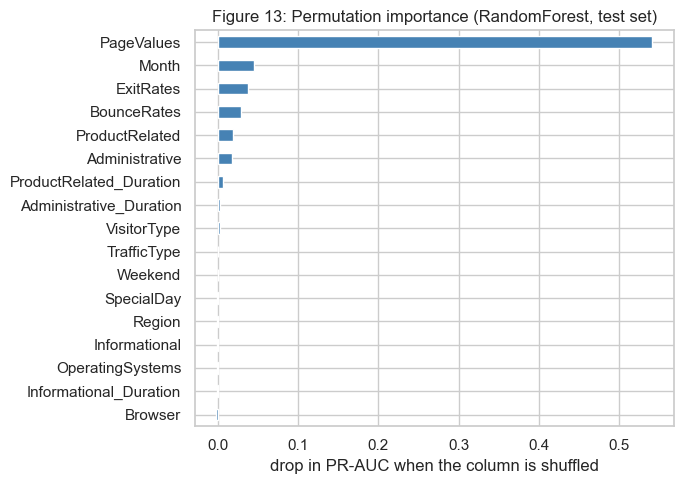

PageValues                 0.5411
Month                      0.0450
ExitRates                  0.0373
BounceRates                0.0292
ProductRelated             0.0192
Administrative             0.0176
ProductRelated_Duration    0.0062
Administrative_Duration    0.0028
VisitorType                0.0027
TrafficType                0.0009
Weekend                    0.0005
SpecialDay                -0.0003
Region                    -0.0003
Informational             -0.0005
OperatingSystems          -0.0006
Informational_Duration    -0.0010
Browser                   -0.0016
dtype: float64


In [26]:
final_name = max(searches, key=lambda k: searches[k].best_score_)
final = searches[final_name].best_estimator_
print("model with best CV PR-AUC:", final_name)

perm = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=10,
                              random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
perm_imp.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("drop in PR-AUC when the column is shuffled")
plt.title("Figure 13: Permutation importance (" + final_name + ", test set)")
save("13_permutation_importance.png")
print(perm_imp.round(4))

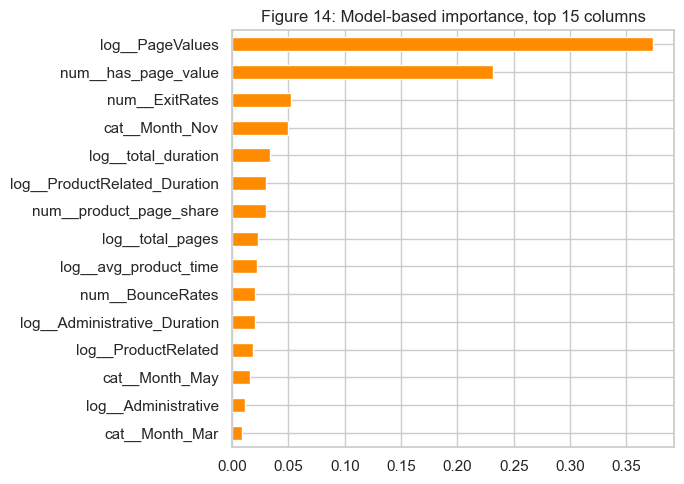

log__PageValues                 0.3735
num__has_page_value             0.2320
num__ExitRates                  0.0519
cat__Month_Nov                  0.0496
log__total_duration             0.0337
log__ProductRelated_Duration    0.0305
num__product_page_share         0.0303
log__total_pages                0.0228
log__avg_product_time           0.0222
num__BounceRates                0.0207
log__Administrative_Duration    0.0207
log__ProductRelated             0.0187
cat__Month_May                  0.0159
log__Administrative             0.0112
cat__Month_Mar                  0.0084
dtype: float64


In [27]:
names = final.named_steps["prep"].get_feature_names_out()
est = final.named_steps["model"]
if hasattr(est, "feature_importances_"):
    mb = pd.Series(est.feature_importances_, index=names)
else:
    mb = pd.Series(np.abs(est.coef_[0]), index=names)
mb = mb.sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 5))
mb.sort_values().plot(kind="barh", color="darkorange")
plt.title("Figure 14: Model-based importance, top 15 columns")
save("14_model_importance.png")
print(mb.round(4))

Both importance methods agree that PageValues is the most important input by a big margin. Shuffling PageValues drops the test PR-AUC by 0.54, while the next inputs are much smaller: Month 0.045, ExitRates 0.037 and BounceRates 0.029. Inside the random forest, PageValues and our has_page_value flag together take about 60% of the total importance, followed by ExitRates and November.

Region, Browser, OperatingSystems, Informational and SpecialDay have importance around zero or slightly negative, which means shuffling them does not hurt the model at all.

Now we check if we can use fewer features. All the options below are inside the pipeline and are scored with the same 5-fold CV on the training set, using the tuned model settings. After preprocessing there are about 80 columns (most of them one-hot columns).

- SelectKBest with mutual information keeps the k columns that share the most information with Revenue.
- RFE (recursive feature elimination) with logistic regression drops the weakest column again and again until 15 are left.
- PCA is a reduction method, it replaces the columns with components that keep 95% of the variance.
- We also tried the model without PageValues (and without our has_page_value flag that comes from it), because PageValues is computed by Google Analytics from pages that led to a transaction, so it is partly built from the outcome and it may not be known early in a live session.

,roc_auc,pr_auc,precision,recall,f1
setup,,,,,
all features,0.933,0.753,0.590,0.794,0.677
SelectKBest k=5,0.896,0.693,0.564,0.796,0.660
SelectKBest k=10,0.901,0.720,0.572,0.785,0.661
SelectKBest k=20,0.921,0.740,0.581,0.782,0.667
RFE (LR) 15 columns,0.920,0.709,0.558,0.805,0.658
PCA 95% variance,0.923,0.727,0.605,0.778,0.680
without PageValues,0.775,0.375,0.356,0.497,0.414


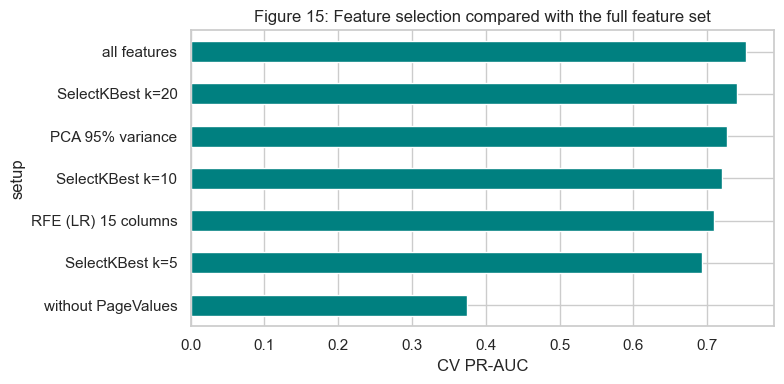

In [28]:
mi = partial(mutual_info_classif, random_state=42)
tuned_model = clone(final.named_steps["model"])
sel_configs = {
    "all features": make_pipe(clone(tuned_model)),
    "SelectKBest k=5": make_pipe(clone(tuned_model), extra=SelectKBest(mi, k=5)),
    "SelectKBest k=10": make_pipe(clone(tuned_model), extra=SelectKBest(mi, k=10)),
    "SelectKBest k=20": make_pipe(clone(tuned_model), extra=SelectKBest(mi, k=20)),
    "RFE (LR) 15 columns": make_pipe(clone(tuned_model), extra=RFE(LogisticRegression(max_iter=2000), n_features_to_select=15)),
    "PCA 95% variance": make_pipe(clone(tuned_model), extra=PCA(n_components=0.95, random_state=42)),
    "without PageValues": make_pipe(clone(tuned_model), drop=("PageValues", "has_page_value")),
}
sel_rows = []
for name, pipe in sel_configs.items():
    sel_rows.append({"setup": name, **cv_scores(pipe)})
sel_table = pd.DataFrame(sel_rows).set_index("setup").round(3)
display(sel_table)
plt.figure(figsize=(8, 4))
sel_table["pr_auc"].sort_values().plot(kind="barh", color="teal")
plt.xlabel("CV PR-AUC")
plt.title("Figure 15: Feature selection compared with the full feature set")
save("15_feature_selection.png")

In [29]:
# which columns did SelectKBest k=10 keep
kb = make_pipe(clone(tuned_model), extra=SelectKBest(mi, k=10)).fit(X_train, y_train)
kept = kb.named_steps["prep"].get_feature_names_out()[kb.named_steps["select"].get_support()]
print(list(kept))

['log__Administrative', 'log__ProductRelated', 'log__ProductRelated_Duration', 'log__PageValues', 'log__total_pages', 'log__total_duration', 'log__avg_product_time', 'num__BounceRates', 'num__ExitRates', 'num__has_page_value']


None of the selection methods beat the full feature set (CV PR-AUC 0.753). SelectKBest with 20 columns came closest (0.740), and with 10 columns it was 0.720. The 10 columns it kept are the ones we expected from the EDA: PageValues, has_page_value, ExitRates, BounceRates and the page counts and durations, with no month or traffic columns. PCA with 95% of the variance got 0.727 and RFE with 15 columns 0.709. So a much smaller model is possible if we accept losing about 0.01 to 0.04 of PR-AUC, but the full model is already small and fast, so we kept all features.

The run without PageValues is the most important result in this section. PR-AUC falls from 0.753 to 0.375 and recall from 0.794 to 0.497. The model depends heavily on this one column. This is a real limitation (section 14), because in a live session PageValues is not fully known until the visitor has reached pages that led to purchases before.

## 10. Final Evaluation on the Test Set

The default 0.5 threshold is not a good choice with 15% buyers. We pick the threshold that gives the best F1 on out-of-fold predictions of the training set (each training row is predicted by a model that did not see it). The test set is not used for this.

In [30]:
oof = cross_val_predict(clone(final), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
p, r, t = precision_recall_curve(y_train, oof)
f1s = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
thr = float(t[np.argmax(f1s)])
print("chosen threshold:", round(thr, 3), "out-of-fold F1 at it:", round(f1s.max(), 3))


def test_metrics(model, threshold=0.5):
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"roc_auc": roc_auc_score(y_test, prob), "pr_auc": average_precision_score(y_test, prob),
            "precision": precision_score(y_test, pred, zero_division=0), "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred), "accuracy": accuracy_score(y_test, pred), "false_alarm_rate": fp / (fp + tn)}


fitted = {
    "Dummy (baseline)": make_pipe(DummyClassifier(strategy="prior")).fit(X_train, y_train),
    "DecisionTree": make_pipe(DecisionTreeClassifier(random_state=42)).fit(X_train, y_train),
}
for name, rs in searches.items():
    fitted[name + " (tuned)"] = rs.best_estimator_
test_rows = [{"model": k, "threshold": 0.5, **test_metrics(v)} for k, v in fitted.items()]
test_rows.append({"model": final_name + " (tuned)", "threshold": round(thr, 3), **test_metrics(final, thr)})
test_table = pd.DataFrame(test_rows).set_index(["model", "threshold"]).round(3)
display(test_table)

chosen threshold: 0.632 out-of-fold F1 at it: 0.69


,,roc_auc,pr_auc,precision,recall,f1,accuracy,false_alarm_rate
model,threshold,,,,,,,
Dummy (baseline),0.500,0.500,0.156,0.000,0.000,0.000,0.844,0.000
DecisionTree,0.500,0.741,0.377,0.542,0.571,0.556,0.857,0.089
LogisticRegression (tuned),0.500,0.928,0.690,0.562,0.817,0.666,0.872,0.118
RandomForest (tuned),0.500,0.933,0.742,0.583,0.791,0.671,0.879,0.105
GradientBoosting (tuned),0.500,0.937,0.756,0.730,0.623,0.672,0.905,0.043
RandomForest (tuned),0.632,0.933,0.742,0.668,0.717,0.692,0.900,0.066


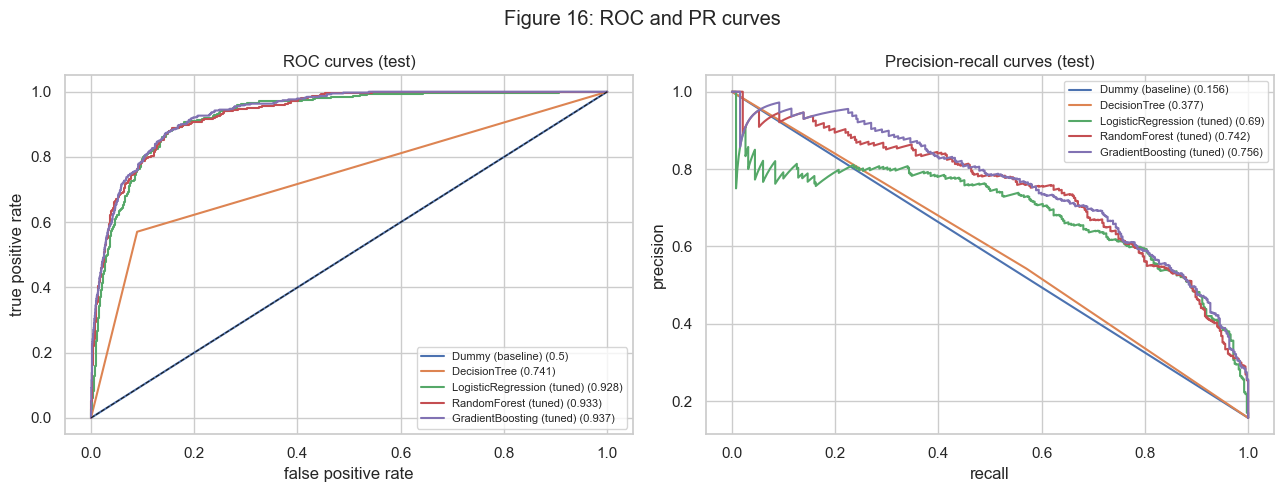

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, model in fitted.items():
    prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    pr, rc, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=name + " (" + str(round(roc_auc_score(y_test, prob), 3)) + ")")
    axes[1].plot(rc, pr, label=name + " (" + str(round(average_precision_score(y_test, prob), 3)) + ")")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves (test)")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves (test)")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
fig.suptitle("Figure 16: ROC and PR curves")
save("16_roc_pr_curves.png")

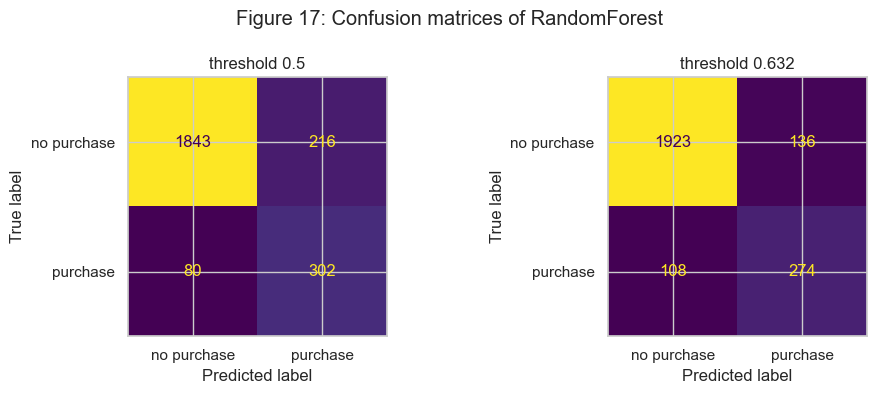

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
p_test = final.predict_proba(X_test)[:, 1]
for ax, th in zip(axes, [0.5, thr]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= th).astype(int)),
                           display_labels=["no purchase", "purchase"]).plot(ax=ax, colorbar=False)
    ax.set_title("threshold " + str(round(th, 3)))
fig.suptitle("Figure 17: Confusion matrices of " + final_name)
save("17_confusion_matrix.png")

Random forest had the best CV PR-AUC, so we chose it as the final model before looking at the test set. The threshold picked from out-of-fold predictions is 0.632 (out-of-fold F1 0.69). It is above 0.5 because the class weights already push the probabilities up.

On the test set the final model gets ROC-AUC 0.933 and PR-AUC 0.742. With the chosen threshold, precision is 0.668, recall 0.717 and F1 0.692, and 6.6% of non-buyers are wrongly flagged (false alarm rate). At 0.5 the same model has higher recall (0.791) but lower precision (0.583) and more false alarms (10.5%), so the threshold does what we wanted. In counts, out of 382 buyers in the test set we catch 274 and miss 108, and we raise 136 false alarms out of 2,059 non-buyers.

Gradient boosting actually did slightly better on the test set (PR-AUC 0.756 against 0.742). In CV the difference was tiny (0.7523 against 0.7532), and we did not want to switch models after seeing the test results, because then the test score would no longer be a fair estimate. Both are clearly better than logistic regression (0.690), the decision tree (0.377) and the baseline (0.156).

## 11. Error Analysis

In [33]:
ea = X_test.copy()
ea["y"] = y_test.values
ea["prob"] = p_test
ea["pred"] = (p_test >= thr).astype(int)
ea["group"] = np.select([(ea.y == 1) & (ea.pred == 1), (ea.y == 1) & (ea.pred == 0), (ea.y == 0) & (ea.pred == 1)],
                        ["TP", "FN", "FP"], "TN")
print(ea["group"].value_counts())
display(ea.groupby("group")[["PageValues", "ProductRelated", "ProductRelated_Duration", "ExitRates", "BounceRates"]].median().round(3))
print("share of sessions with PageValues = 0 in each group:")
print(ea.groupby("group")["PageValues"].apply(lambda s: (s == 0).mean()).round(3))
display(pd.crosstab(ea["group"], ea["VisitorType"], normalize="index").round(2))

group
TN    1923
TP     274
FP     136
FN     108
Name: count, dtype: int64


,PageValues,ProductRelated,ProductRelated_Duration,ExitRates,BounceRates
group,,,,,
FN,0.000,37.5,1429.365,0.023,0.003
FP,17.426,35.0,1250.709,0.018,0.002
TN,0.000,15.0,455.500,0.029,0.005
TP,27.860,25.0,915.724,0.013,0.000


share of sessions with PageValues = 0 in each group:
group
FN    0.648
FP    0.037
TN    0.947
TP    0.007
Name: PageValues, dtype: float64


VisitorType,New_Visitor,Other,Returning_Visitor
group,,,
FN,0.21,0.00,0.79
FP,0.05,0.01,0.94
TN,0.12,0.01,0.87
TP,0.27,0.00,0.73


In [34]:
buyers = ea[ea.y == 1]
print("recall by month:")
print(buyers.groupby("Month")["pred"].agg(["count", "mean"]).reindex(month_order).dropna().round(3))
print("recall by visitor type:")
print(buyers.groupby("VisitorType")["pred"].agg(["count", "mean"]).round(3))
print("false alarm rate by month:")
print(ea[ea.y == 0].groupby("Month")["pred"].mean().reindex(month_order).round(3))

recall by month:
       count   mean
Month              
Mar     33.0  0.879
May     79.0  0.797
June     6.0  0.500
Jul     15.0  0.667
Aug     14.0  0.643
Sep     19.0  0.632
Oct     18.0  0.778
Nov    161.0  0.677
Dec     37.0  0.676
recall by visitor type:
                   count   mean
VisitorType                    
New_Visitor           97  0.763
Returning_Visitor    285  0.702
false alarm rate by month:
Month
Feb     0.000
Mar     0.031
May     0.066
June    0.037
Jul     0.078
Aug     0.068
Sep     0.107
Oct     0.082
Nov     0.112
Dec     0.029
Name: pred, dtype: float64


Most of the mistakes are about PageValues. 64.8% of the missed buyers (false negatives) have PageValues = 0, while only 0.7% of the buyers we found do. When a buyer never reached a page with a page value, the model has very little to go on. These missed buyers are not short visits though, their median is 37.5 product pages and about 1,429 seconds on product pages, which is more than the buyers we found. The false alarms are the opposite case: 96.3% of them have PageValues above 0 (median 17.4), so they look like buyers but did not buy.

Recall is similar for new (0.763) and returning visitors (0.702). By month it is highest in March (0.879) and May (0.797) and lower in November (0.677) and December (0.676), even though November has the most buyers. False alarms are highest in November (11.2%) and September (10.7%), so in busy months the model flags more people who do not buy in the end. Months like June, July and August have only 6 to 15 buyers in the test set, so their recall values are not very reliable.

What this tells us about conversion: a purchase is mostly linked to reaching pages with a page value, a low exit rate, longer product browsing, and the November period. A long session alone is not enough.

## 12. K-Means Segments of Browsing Sessions

Here we look for groups of sessions with similar browsing behavior. We use the 6 page count and duration columns plus BounceRates, ExitRates and PageValues. They are log1p transformed (very skewed) and standardized, because K-Means uses distances and the durations would dominate otherwise. K-Means is fitted on the training set only. Revenue is not an input, it is only used afterwards to describe the groups.

,inertia,silhouette,davies_bouldin
k,,,
2,62014.242,0.288,1.398
3,44735.941,0.392,0.967
4,32468.895,0.355,1.012
5,27431.888,0.364,0.963
6,24128.787,0.328,1.007
7,21848.493,0.324,1.160
8,20034.453,0.305,1.182
9,18504.087,0.313,1.162
10,17177.605,0.318,1.173


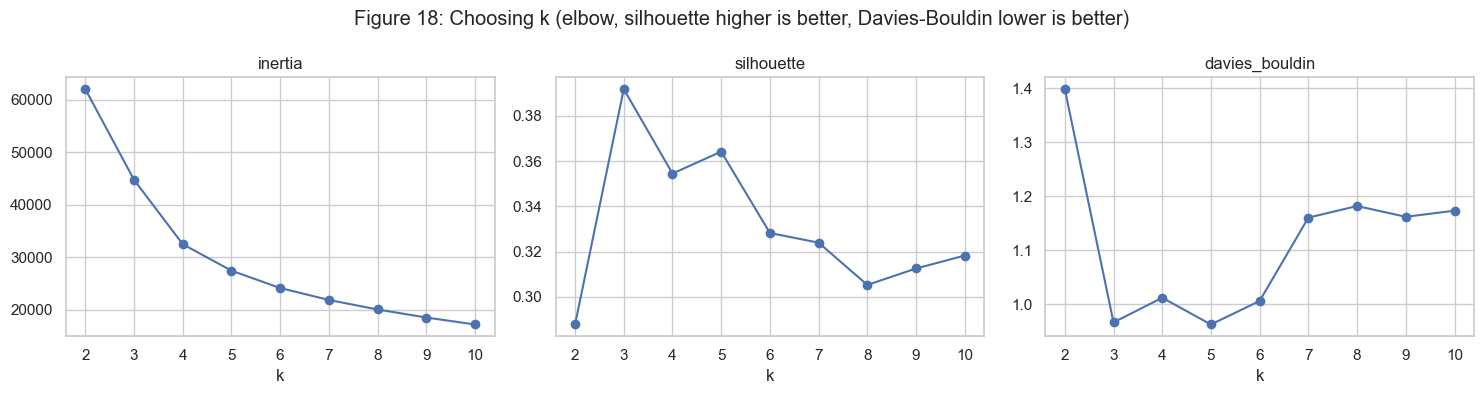

In [35]:
km_cols = num_raw[:-1]
scaler_pipe = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler())])
Z = scaler_pipe.fit_transform(X_train[km_cols])
k_rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                   "davies_bouldin": davies_bouldin_score(Z, km.labels_)})
k_table = pd.DataFrame(k_rows).set_index("k")
display(k_table.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["inertia", "silhouette", "davies_bouldin"]):
    ax.plot(k_table.index, k_table[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("k")
fig.suptitle("Figure 18: Choosing k (elbow, silhouette higher is better, Davies-Bouldin lower is better)")
save("18_choose_k.png")

In [36]:
# how big are the clusters for the k values that look good
for k in [3, 4, 5]:
    sizes = pd.Series(KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Z)).value_counts(normalize=True)
    print("k =", k, "cluster shares:", sizes.round(3).tolist())

k = 3 cluster shares: [0.74, 0.189, 0.071]
k = 4 cluster shares: [0.414, 0.341, 0.18, 0.065]
k = 5 cluster shares: [0.372, 0.261, 0.174, 0.129, 0.064]


The inertia drops quickly up to k = 4 or 5 and then flattens. The silhouette score is highest at k = 3 (0.392), but k = 5 is close (0.364) and has the lowest Davies-Bouldin index (0.963). With k = 3 one cluster holds about 74% of all training sessions, so it does not separate much. With k = 5 the sessions with a page value get their own group, which is the most useful split for the shop. So we chose k = 5.

In [37]:
K = 5
seg = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scale", StandardScaler()),
                ("km", KMeans(n_clusters=K, n_init=10, random_state=42))]).fit(X_train[km_cols])
train_seg = seg.predict(X_train[km_cols])
prof = X_train[km_cols].assign(cluster=train_seg).groupby("cluster").median()
prof["sessions"] = pd.Series(train_seg).value_counts().sort_index()
prof["conversion"] = pd.Series(y_train.values).groupby(train_seg).mean()
prof["share PageValues > 0"] = (X_train["PageValues"] > 0).groupby(train_seg).mean().values
prof["new_visitor_share"] = (X_train["VisitorType"] == "New_Visitor").groupby(train_seg).mean().values
display(prof.round(3))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,sessions,conversion,share PageValues > 0,new_visitor_share
cluster,,,,,,,,,,,,,
0,3.0,79.350,0.0,0.0,21.0,659.786,0.000,0.019,0.000,2548,0.068,0.054,0.236
1,0.0,0.000,0.0,0.0,1.0,0.000,0.200,0.200,0.000,624,0.005,0.000,0.042
2,4.0,114.875,2.0,92.0,45.0,1714.824,0.004,0.019,0.000,1702,0.227,0.438,0.100
3,0.0,0.000,0.0,0.0,11.0,334.750,0.000,0.039,0.000,3631,0.036,0.013,0.082
4,2.0,47.071,0.0,0.0,28.0,1059.575,0.000,0.016,24.131,1259,0.662,1.000,0.203


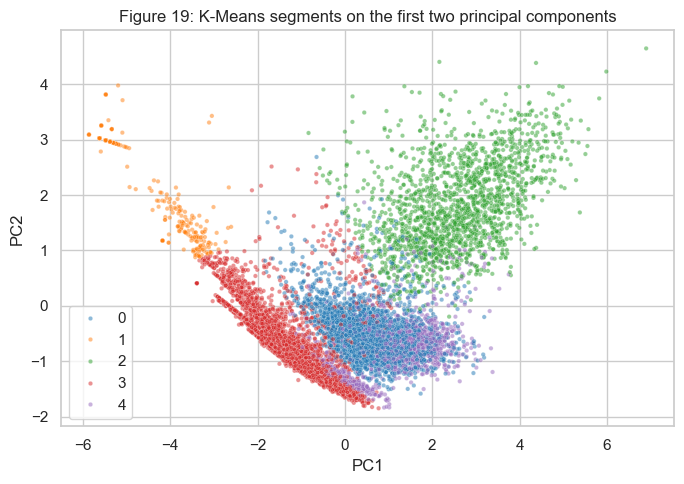

variance explained by 2 components: 0.67


In [38]:
pca2 = PCA(n_components=2, random_state=42).fit(Z)
P = pca2.transform(Z)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=train_seg, palette="tab10", s=10, alpha=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Figure 19: K-Means segments on the first two principal components")
save("19_segments_pca.png")
print("variance explained by 2 components:", round(pca2.explained_variance_ratio_.sum(), 3))

,train conversion,test conversion,test sessions
account and product browsing,0.068,0.055,641
one-page bouncers,0.005,0.006,157
long research sessions,0.227,0.256,425
short product browsing,0.036,0.041,913
high page value,0.662,0.656,305


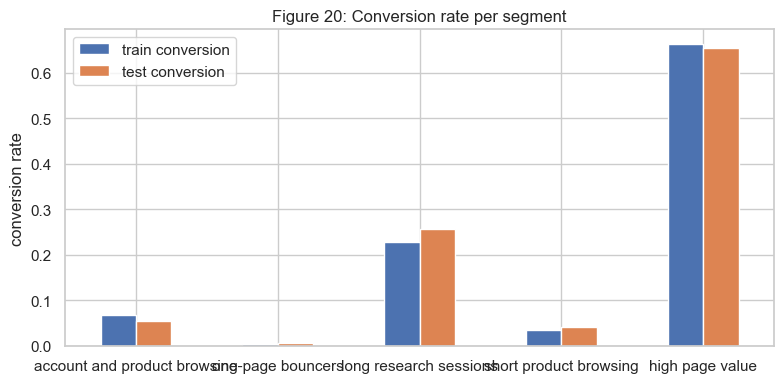

In [39]:
seg_names = {0: "account and product browsing", 1: "one-page bouncers", 2: "long research sessions",
             3: "short product browsing", 4: "high page value"}
test_seg = seg.predict(X_test[km_cols])
check = pd.DataFrame({"train conversion": prof["conversion"],
                      "test conversion": pd.Series(y_test.values).groupby(test_seg).mean(),
                      "test sessions": pd.Series(test_seg).value_counts().sort_index()})
check.index = [seg_names[i] for i in check.index]
display(check.round(3))
plt.figure(figsize=(8, 4))
check[["train conversion", "test conversion"]].plot(kind="bar", rot=0, ax=plt.gca())
plt.ylabel("conversion rate")
plt.title("Figure 20: Conversion rate per segment")
save("20_segment_conversion.png")

The five segments (medians on the training set):

1. High page value (cluster 4, 1,259 sessions): median PageValues 24.1, 28 product pages and a low exit rate. 66.2% of these sessions end with a purchase.
2. Long research sessions (cluster 2, 1,702 sessions): the longest visits, 45 product pages and about 1,715 seconds on them, and the only group that also reads informational pages. Conversion 22.7%.
3. Account and product browsing (cluster 0, 2,548 sessions): around 3 administrative pages and 21 product pages, but no page value. Conversion 6.8%.
4. Short product browsing (cluster 3, 3,631 sessions): 11 product pages in about 335 seconds and no administrative pages. This is the biggest group but only 3.6% buy.
5. One-page bouncers (cluster 1, 624 sessions): one page, bounce and exit rate of 0.2. Almost nobody buys (0.5%).

On the test set the conversion per segment is very close (65.6% for high page value, 25.6% for long research, 5.5%, 4.1% and 0.6% for the others), so the segments hold on data K-Means did not see. In the PCA scatter (the first two components keep 67% of the variance) the bouncers are a separate group, while the other segments touch each other, which is normal for behavior data.

## 13. Findings

In [40]:
full = df.copy()
print("conversion PageValues > 0:", round(full.loc[full.PageValues > 0, "Revenue"].mean(), 3),
      "PageValues = 0:", round(full.loc[full.PageValues == 0, "Revenue"].mean(), 3))
print("Nov conversion:", round(full.loc[full.Month == "Nov", "Revenue"].mean(), 3),
      "share of all buyers in Nov:", round((full.loc[full.Revenue, "Month"] == "Nov").mean(), 3))
print("May sessions share:", round((full.Month == "May").mean(), 3), "May conversion:", round(full.loc[full.Month == "May", "Revenue"].mean(), 3))
print(full.groupby("VisitorType")["Revenue"].mean().round(3))
print("conversion SpecialDay > 0:", round(full.loc[full.SpecialDay > 0, "Revenue"].mean(), 3),
      "SpecialDay = 0:", round(full.loc[full.SpecialDay == 0, "Revenue"].mean(), 3))
print(full.groupby(pd.qcut(full["ExitRates"], 4, duplicates="drop"))["Revenue"].mean().round(3))

conversion PageValues > 0: 0.563 PageValues = 0: 0.039
Nov conversion: 0.255 share of all buyers in Nov: 0.398
May sessions share: 0.273 May conversion: 0.11
VisitorType
New_Visitor          0.249
Other                0.198
Returning_Visitor    0.141
Name: Revenue, dtype: float64
conversion SpecialDay > 0: 0.062 SpecialDay = 0: 0.167
ExitRates
(-0.001, 0.0142]    0.267
(0.0142, 0.025]     0.203
(0.025, 0.0485]     0.123
(0.0485, 0.2]       0.031
Name: Revenue, dtype: float64


1. Reaching a page with a page value is the main sign of a purchase. 56.3% of sessions with PageValues above 0 convert, against 3.9% of the rest. The shop could treat a session as "hot" as soon as the visitor reaches such a page, for example by showing the cart or a delivery offer at that point. Even in our high page value segment about a third of visitors leave without buying, so that step is worth studying.

2. November brings 39.8% of all buyers with a 25.4% conversion rate, while May has the most traffic (27.3% of sessions) but only 11.0% conversion. Marketing budget and stock should be heaviest before and during November, and in May the problem is turning visitors into buyers, not getting more visitors.

3. New visitors convert better (24.9%) than returning ones (14.1%). Returning visitors are the majority, so even a small gain for them adds up. Reminders of items they viewed before, or saved carts, could target this group.

4. Exit rate is a strong warning sign. Sessions in the highest quarter of ExitRates convert at 3.1%, against 26.7% in the lowest quarter. Pages with high exit rates should be checked first (slow pages, missing product information, shipping cost shown too late).

5. Sessions near special days convert much worse (6.2% against 16.7%). Visitors seem to browse for gifts early without buying. Campaigns before Valentine's Day and Mother's Day could push earlier decisions, for example with a clear "order by" date for delivery in time.

6. The short product browsing segment is the largest (3,631 training sessions) but only 3.6% of it converts. Better recommendations or search on the first product pages could move some of these visitors towards the long research or high page value behavior.

7. Traffic sources differ a lot. Type 2 brings the most sessions and converts at 21.6%, while types 3 and 13 convert under 9%. If the shop matches these codes to its real channels, spending could move from the weak sources to the strong ones.

## 14. Limitations and Future Work

### Limitations

1. The model leans on PageValues. Without it CV PR-AUC drops from 0.753 to 0.375. PageValues is computed by Google Analytics from pages that led to past transactions, so it is partly linked to the outcome, and it is not fully known early in a live session. Our model is good at the end of a session but weak as an early warning.
2. The data is one shop over one year. January and April are missing and May and November alone are about half of all sessions. We used a random split, so we never tested training on earlier months and predicting later ones. We do not know how much the score drops when behavior changes (next year, new campaigns).
3. OperatingSystems, Browser, Region and TrafficType are only codes, and there is no product, price or page order information. Some findings (like the traffic types) cannot be turned into exact actions, and we cannot model the order in which pages were visited.
4. The threshold maximizes F1, which treats a missed buyer and a false alarm as equally bad. In a real shop these have different costs. Also, because of the class weights, the probabilities are pushed up and are not calibrated, so "70%" in the app does not exactly mean a 70% chance.
5. The app does not store predictions or check if the incoming data looks different from the training data, and the free Streamlit hosting goes to sleep when nobody uses it.

### Future improvements

1. Time-based validation. Why: limitation 2, we do not know how the model handles change over time. How: sort sessions by month, train on February to October and test on November and December, with the same pipeline and tuning. If the score drops a lot, retrain every month on a sliding window. Metric: the gap between PR-AUC on the time split and our random-split test PR-AUC (0.742). A small gap means the current results are trustworthy.
2. Early-session model without PageValues. Why: limitation 1, the shop needs a prediction while the visitor is still browsing. How: train a second model without PageValues and has_page_value, add features that are known early (pages per minute, product share in the first pages if page order data is collected), tune random forest and gradient boosting again, and let the app switch between the "early" and "full" model. Metric: CV PR-AUC and recall at precision 0.5 compared with our 0.375 run without PageValues.
3. Probability calibration. Why: limitation 4, the probabilities shown in the app should mean what they say. How: wrap the final random forest in CalibratedClassifierCV (isotonic, 5 folds) on the training set and pick the threshold again from out-of-fold predictions. Metric: Brier score and a reliability curve on the test set before and after. PR-AUC should stay about the same.
4. Cost-based threshold. Why: limitation 4, F1 is not what the business cares about. How: get from the shop the cost of targeting a non-buyer (for example a discount) and the gain from converting a buyer, compute the expected profit for every threshold on out-of-fold predictions, and use the threshold with the highest profit. Add the costs as inputs in the app. Metric: expected profit on the test set compared with the F1-based threshold.
5. Prediction logging and drift checks. Why: limitation 5. How: save each scored session with a timestamp to a small database, and once a month compute the Population Stability Index (PSI) of every input against the training data, flagging columns with PSI above 0.2. When real labels come in, recompute PR-AUC. Metric: PSI per column over time and PR-AUC on new labelled data.

| Improvement | Expected impact | Feasibility | Priority |
|---|---|---|---|
| Time-based validation | High | High (same data, small code change) | 1 |
| Early-session model without PageValues | High | Medium (best version needs page order data) | 2 |
| Probability calibration | Medium | High | 3 |
| Cost-based threshold | Medium | Medium (needs real cost numbers from the shop) | 4 |
| Prediction logging and drift checks | Medium | Low on free hosting | 5 |

## 15. Saving the Models for the App

In [41]:
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(final, ROOT / "models" / "purchase_model.joblib", compress=3)
joblib.dump(seg, ROOT / "models" / "session_kmeans.joblib", compress=3)

med_cols = NUM_INPUTS
info = {
    "final_model": final_name,
    "best_params": {k: str(v) for k, v in searches[final_name].best_params_.items()},
    "threshold": thr,
    "sklearn_version": sklearn.__version__,
    "input_columns": INPUT_COLS,
    "month_order": month_order,
    "categories": {c: sorted(X_train[c].unique().tolist()) for c in CAT_COLS},
    "special_day_values": sorted(X_train["SpecialDay"].unique().tolist()),
    "numeric_ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in NUM_INPUTS},
    "defaults": {**{c: float(X_train[c].median()) for c in NUM_INPUTS},
                 **{c: X_train[c].mode()[0] for c in CAT_COLS}},
    "buyer_medians": X_train[y_train == 1][med_cols].median().round(4).to_dict(),
    "nonbuyer_medians": X_train[y_train == 0][med_cols].median().round(4).to_dict(),
    "permutation_importance": perm_imp.round(5).to_dict(),
    "test_metrics": {f"{m} @ {t}": v for (m, t), v in test_table.to_dict(orient="index").items()},
    "segments": {"k": K, "columns": km_cols, "names": {str(k): v for k, v in seg_names.items()},
                 "sessions": prof["sessions"].astype(int).to_dict(), "conversion": prof["conversion"].round(4).to_dict(),
                 "profile": prof[km_cols].round(3).to_dict(orient="index")},
}
info["defaults"] = {k: (v.item() if hasattr(v, "item") else v) for k, v in info["defaults"].items()}
info["segments"]["sessions"] = {str(k): v for k, v in info["segments"]["sessions"].items()}
info["segments"]["conversion"] = {str(k): v for k, v in info["segments"]["conversion"].items()}
info["segments"]["profile"] = {str(k): v for k, v in info["segments"]["profile"].items()}
with open(ROOT / "models" / "model_info.json", "w") as f:
    json.dump(info, f, indent=2)

pd.DataFrame({"y_true": y_test.values, "y_prob": p_test}).to_csv(ROOT / "models" / "test_predictions.csv", index=False)
sample = X_test.head(40).copy()
sample["Revenue"] = y_test.head(40).astype(bool).values
sample.to_csv(ROOT / "data" / "sample_sessions.csv", index=False)
print("saved. model file size (MB):", round((ROOT / "models" / "purchase_model.joblib").stat().st_size / 1e6, 2))

saved. model file size (MB): 5.4
